In [166]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [167]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22283 entries, 1007_s_at to AFFX-TrpnX-M_at
Columns: 286 entries, GSM36777 to GSM37062
dtypes: float64(286)
memory usage: 49.3+ MB


In [168]:
missing_values = df.isnull().sum().sum()

print("Total Missing Values:", missing_values)

Total Missing Values: 0


In [169]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [170]:
df.describe()

,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,GSM36786,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
count,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,...,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000,22283.000000
mean,913.726029,973.443037,1000.324961,1034.967226,985.429413,976.049280,1003.429238,1041.481475,880.943661,921.157806,...,1106.546677,971.266095,994.415729,1049.199574,1029.824328,973.229184,966.519284,1032.832074,995.133075,967.102800
std,2732.391933,3371.973081,3529.034928,3891.188255,3552.996340,3291.487254,3554.909054,3981.992575,2484.467638,2811.556954,...,4880.932095,3332.467216,3675.468976,4175.040036,3779.680783,3230.747671,3220.683530,3966.048197,3479.528686,3209.529465
min,0.500000,0.800000,0.300000,0.400000,0.800000,0.100000,0.200000,0.500000,0.900000,0.300000,...,1.100000,0.800000,0.600000,0.900000,0.300000,0.200000,0.300000,0.300000,0.900000,0.400000
25%,68.950000,88.500000,60.800000,77.750000,85.550000,78.800000,61.800000,90.700000,84.600000,71.200000,...,76.300000,75.150000,75.900000,84.100000,69.800000,63.700000,72.800000,84.750000,73.200000,70.400000
50%,236.100000,279.200000,216.000000,257.600000,269.900000,253.400000,215.700000,280.300000,259.800000,232.900000,...,250.100000,247.700000,246.000000,261.700000,232.300000,230.000000,238.600000,267.600000,238.500000,228.000000
75%,711.350000,702.850000,676.800000,702.350000,732.700000,715.350000,691.300000,725.150000,700.650000,712.800000,...,714.000000,689.250000,700.850000,724.350000,671.350000,685.800000,708.450000,711.000000,695.050000,684.050000
max,40917.100000,68495.300000,64802.100000,94763.800000,75816.400000,53982.200000,58133.000000,78481.500000,40938.600000,40874.400000,...,146868.800000,85468.000000,95436.100000,91334.400000,70987.300000,57830.100000,52801.800000,70982.900000,65418.400000,51943.700000


In [171]:
print(df.dtypes.value_counts())

print("\nData types of first 10 columns:")
print(df.dtypes.head(10))

float64    286
Name: count, dtype: int64

Data types of first 10 columns:
GSM36777    float64
GSM36778    float64
GSM36779    float64
GSM36780    float64
GSM36781    float64
GSM36782    float64
GSM36783    float64
GSM36784    float64
GSM36785    float64
GSM36786    float64
dtype: object


In [172]:
print("Duplicate Probe IDs:", df.index.duplicated().sum())

Duplicate Probe IDs: 0


In [173]:
print("Infinite values:",
      np.isinf(df.select_dtypes(include="number")).sum().sum())

Infinite values: 0


In [174]:
print("Minimum value:", df.min().min())

print("Maximum value:", df.max().max())

Minimum value: 0.1
Maximum value: 157291.8


In [175]:
# Calculate numerical summary

Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = ((df < lower_limit) | (df > upper_limit)).sum().sum()

print("Total potential outliers:", outliers)

Total potential outliers: 683846


In [176]:
# Count potential outliers in each sample

outlier_counts = ((df < lower_limit) |
                  (df > upper_limit)).sum()

print(outlier_counts.sort_values(ascending=False).head(10))

GSM36881    2658
GSM36968    2621
GSM36900    2621
GSM36899    2609
GSM36947    2603
GSM36856    2591
GSM36942    2588
GSM37003    2574
GSM36886    2574
GSM36948    2568
dtype: int64


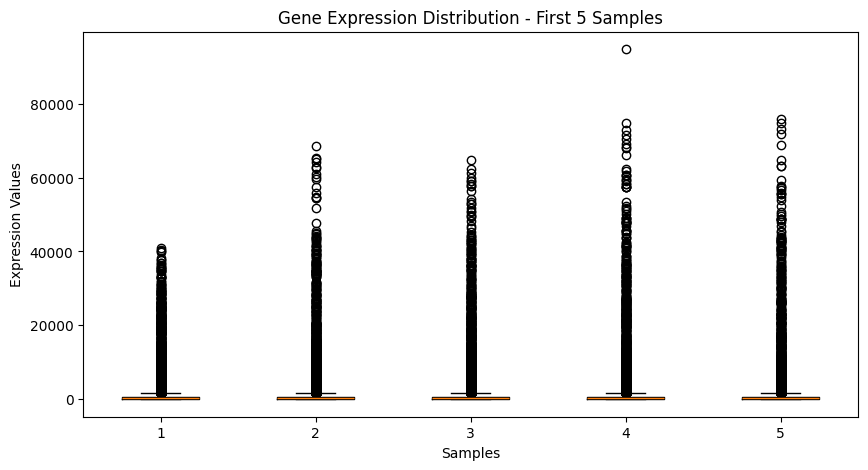

In [177]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.boxplot(df.iloc[:, :5].values)

plt.title("Gene Expression Distribution - First 5 Samples")
plt.xlabel("Samples")
plt.ylabel("Expression Values")
plt.show()

In [178]:
# Apply log2 transformation

df_log2 = np.log2(df)

print("Log2 transformation completed!")

print("Original minimum:", df.min().min())
print("Transformed minimum:", df_log2.min().min())

print("Original maximum:", df.max().max())
print("Transformed maximum:", df_log2.max().max())

Log2 transformation completed!
Original minimum: 0.1
Transformed minimum: -3.321928094887362
Original maximum: 157291.8
Transformed maximum: 17.263083935987005


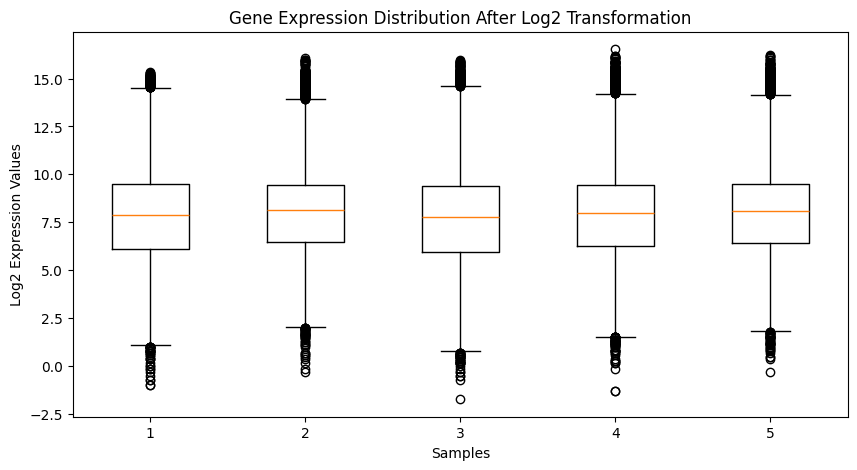

In [179]:
plt.figure(figsize=(10, 5))

plt.boxplot(df_log2.iloc[:, :5].values)

plt.title("Gene Expression Distribution After Log2 Transformation")
plt.xlabel("Samples")
plt.ylabel("Log2 Expression Values")

plt.show()

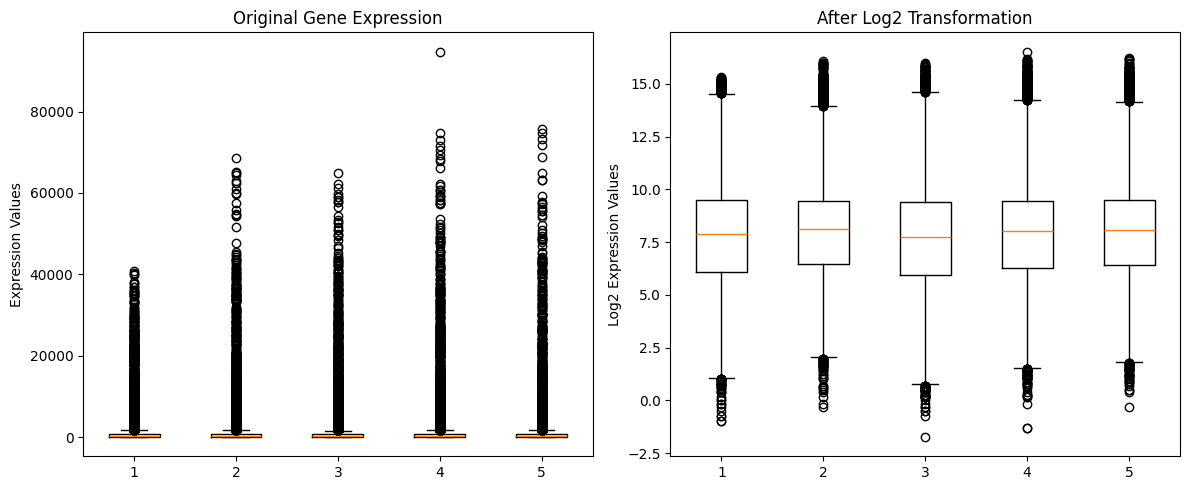

In [180]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df.iloc[:, :5].values)
axes[0].set_title("Original Gene Expression")
axes[0].set_ylabel("Expression Values")

axes[1].boxplot(df_log2.iloc[:, :5].values)
axes[1].set_title("After Log2 Transformation")
axes[1].set_ylabel("Log2 Expression Values")

plt.tight_layout()
plt.show()

In [181]:
import pandas as pd

url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE2nnn/GSE2034/matrix/GSE2034_series_matrix.txt.gz"

df = pd.read_csv(
    url,
    sep="\t",
    compression="gzip",
    comment="!",
    index_col=0
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (22283, 286)


,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,GSM36786,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,3848.1,6520.9,5285.7,4043.7,4263.6,2949.8,5498.9,3863.1,3370.4,3991.9,...,4058.2,4017.6,2841.0,2914.2,3681.0,3066.9,2773.0,2984.3,3540.0,2620.0
1053_at,228.9,112.5,178.4,398.7,417.7,221.2,280.4,198.2,304.7,198.2,...,183.4,356.1,234.6,169.4,94.5,265.5,209.8,160.0,285.7,180.5
117_at,213.1,189.8,269.7,312.4,327.1,225.0,243.5,244.4,348.5,185.3,...,326.6,234.9,369.6,149.5,236.4,347.9,226.7,252.9,135.1,191.8
121_at,1009.4,2083.3,1203.4,1104.4,1043.3,1117.6,1085.4,1423.1,1196.4,993.3,...,1041.3,1195.6,751.5,1117.8,1022.4,1127.4,1071.8,1178.5,1256.7,1284.6
1255_g_at,31.8,145.8,42.5,108.2,69.2,47.4,84.3,102.0,22.8,86.3,...,143.5,32.7,62.6,43.0,100.5,47.0,45.1,146.3,75.9,87.4


In [182]:
df_log2.to_csv("GSE2034_log2_transformed.csv")

print("Transformed dataset saved successfully!")

Transformed dataset saved successfully!
